In [62]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [63]:
df = pd.read_csv("ai_job_impact.csv")

In [64]:
df

,Employee_ID,Age,Gender,Education_Level,Industry,Job_Role,Years_Experience,AI_Adoption_Level,Automation_Risk,Upskilling_Required,Salary_Before_AI,Salary_After_AI,Job_Status,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,Productivity_Change_%
0,E0001,50,Female,Bachelor,Marketing,Content Creator,26,High,High,Yes,106820,95455,Replaced,45,No,5,-10.64
1,E0002,45,Male,High School,Manufacturing,Quality Inspector,19,Low,Low,Yes,74131,72013,Unchanged,36,Yes,6,19.05
2,E0003,51,Female,Master,IT,DevOps Engineer,28,Medium,Medium,Yes,35311,42290,Modified,46,Yes,3,17.05
3,E0004,48,Male,PhD,Education,Teacher,24,Medium,Medium,Yes,114478,107820,Modified,50,No,9,-2.47
4,E0005,24,Male,Bachelor,Healthcare,Doctor,0,High,Medium,No,33890,40945,Modified,52,Yes,6,7.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,E1996,55,Other,PhD,Healthcare,Technician,30,Medium,Low,Yes,99082,101090,Unchanged,52,Yes,7,25.67
1996,E1997,31,Male,PhD,Finance,Investment Analyst,9,High,Medium,Yes,32379,44653,Modified,52,Yes,8,9.38
1997,E1998,43,Female,Bachelor,Retail,Cashier,17,High,High,No,53424,74715,Modified,49,Yes,6,-0.57
1998,E1999,43,Female,Bachelor,Marketing,Digital Marketer,20,Medium,Low,No,57821,68499,Unchanged,41,No,9,9.31


In [81]:
data = {
    'Country': [
        'UAE','Singapore','India','China','Japan','South Korea',
        'UK','France','Germany','Spain','Italy','Netherlands','Norway','Ireland',
        'USA','Canada','Mexico',
        'Brazil','Argentina',
        'Australia','New Zealand',
        'South Africa','Nigeria','Egypt'
    ],
    
    'Continent': [
        'Asia','Asia','Asia','Asia','Asia','Asia',
        'Europe','Europe','Europe','Europe','Europe','Europe','Europe','Europe',
        'North America','North America','North America',
        'South America','South America',
        'Oceania','Oceania',
        'Africa','Africa','Africa'
    ],
    
    'AI_Adoption_%': [
        64,60.9,59,50,45,30.7,
        38.9,44,40,41.8,35,38.9,46.4,44.6,
        42,35,28,
        25,22,
        40,35,
        28,20,26
    ]
}

df_country = pd.DataFrame(data)
print(df_country)

         Country      Continent  AI_Adoption_%
0            UAE           Asia           64.0
1      Singapore           Asia           60.9
2          India           Asia           59.0
3          China           Asia           50.0
4          Japan           Asia           45.0
5    South Korea           Asia           30.7
6             UK         Europe           38.9
7         France         Europe           44.0
8        Germany         Europe           40.0
9          Spain         Europe           41.8
10         Italy         Europe           35.0
11   Netherlands         Europe           38.9
12        Norway         Europe           46.4
13       Ireland         Europe           44.6
14           USA  North America           42.0
15        Canada  North America           35.0
16        Mexico  North America           28.0
17        Brazil  South America           25.0
18     Argentina  South America           22.0
19     Australia        Oceania           40.0
20   New Zeal

In [66]:
df.shape

(2000, 17)

In [67]:
df.isnull().sum()

Employee_ID              0
Age                      0
Gender                   0
Education_Level          0
Industry                 0
Job_Role                 0
Years_Experience         0
AI_Adoption_Level        0
Automation_Risk          0
Upskilling_Required      0
Salary_Before_AI         0
Salary_After_AI          0
Job_Status               0
Work_Hours_Per_Week      0
Remote_Work              0
Job_Satisfaction         0
Productivity_Change_%    0
dtype: int64

In [68]:
import seaborn as sns

<Axes: xlabel='Age'>

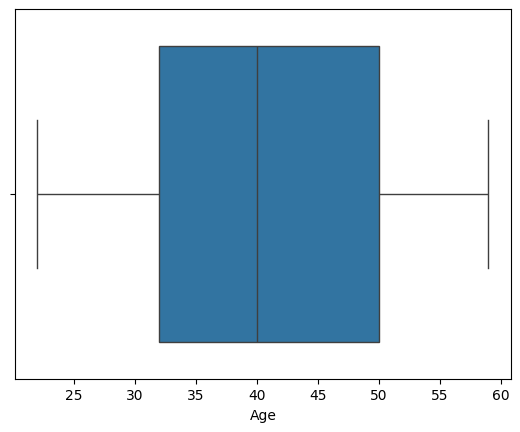

In [69]:
sns.boxplot(x="Age",data=df)                

<Axes: xlabel='Years_Experience'>

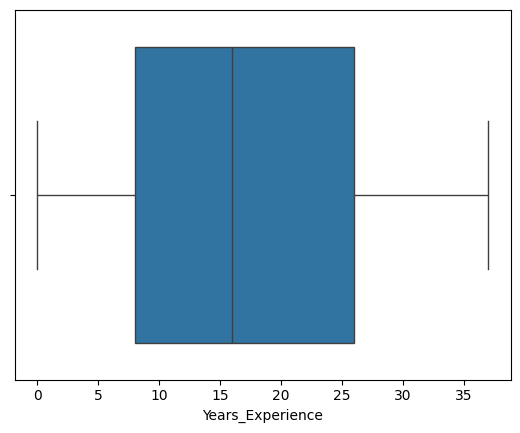

In [70]:
sns.boxplot(x="Years_Experience",data=df)                

<Axes: xlabel='Salary_Before_AI'>

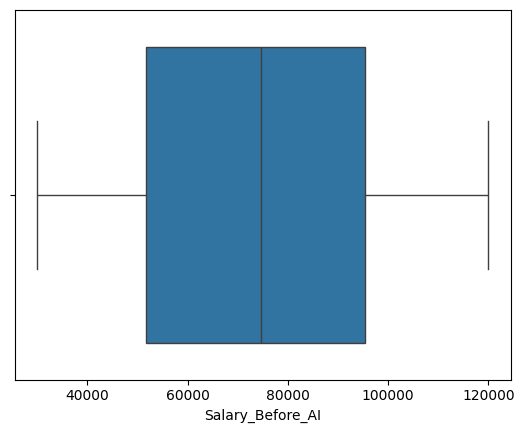

In [71]:
sns.boxplot(x="Salary_Before_AI",data=df)                

<Axes: xlabel='Salary_After_AI'>

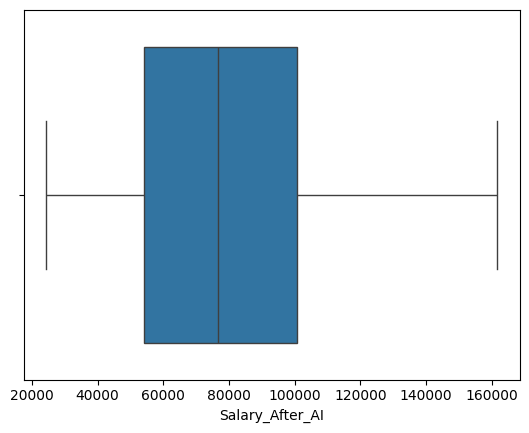

In [72]:
sns.boxplot(x="Salary_After_AI",data=df)                

<Axes: xlabel='Work_Hours_Per_Week'>

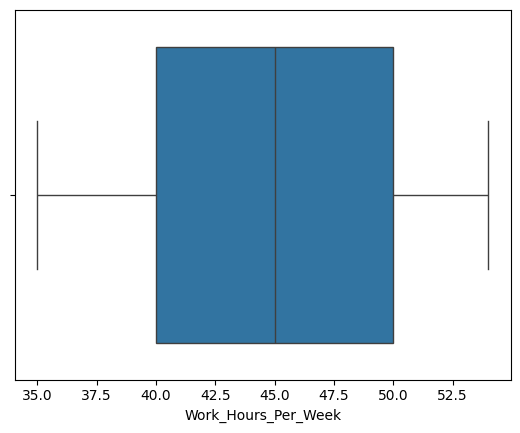

In [73]:
sns.boxplot(x="Work_Hours_Per_Week",data=df)                

<Axes: xlabel='Job_Satisfaction'>

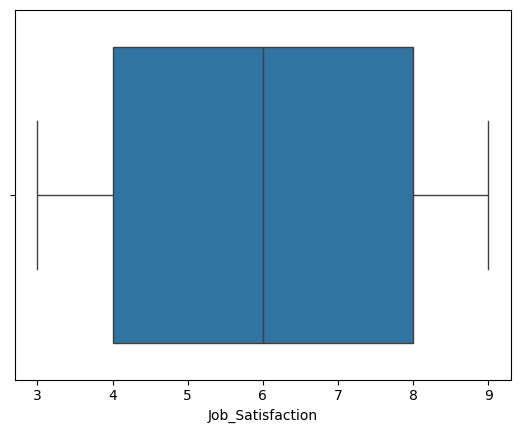

In [74]:
sns.boxplot(x="Job_Satisfaction",data=df)                

<Axes: xlabel='Productivity_Change_%'>

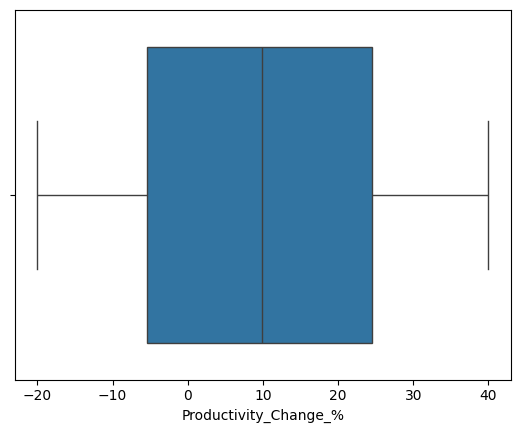

In [75]:
sns.boxplot(x="Productivity_Change_%",data=df)                

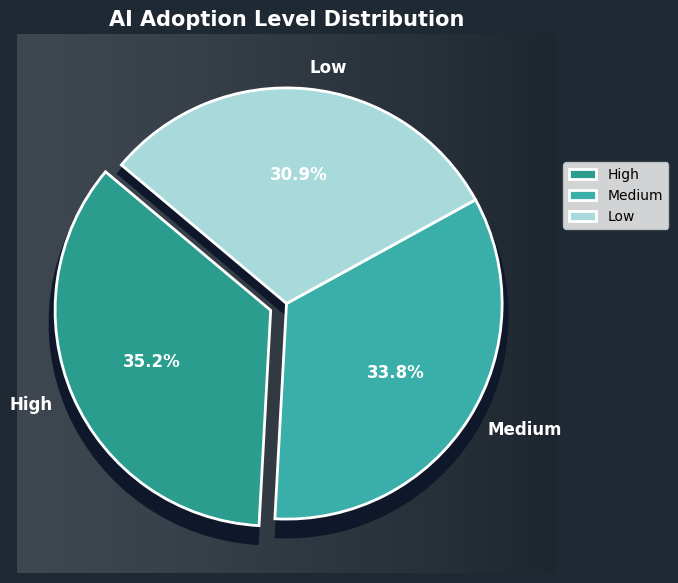

In [76]:
data = df['AI_Adoption_Level'].value_counts()

# Explode first slice
explode = [0.08] + [0]*(len(data)-1)

# 🎨 Professional teal color palette (matching bar & line chart)
colors = ['#2a9d8f', '#3aafa9', '#a8dadc']

# Create figure
fig, ax = plt.subplots(figsize=(7,7))

# 🌌 Background (same as bar/line)
fig.patch.set_facecolor('#1f2933')
ax.set_facecolor('#1f2933')

# 🌫️ Subtle gradient (professional)
gradient = np.linspace(0, 1, 256)
gradient = np.vstack((gradient, gradient))
ax.imshow(gradient, aspect='auto', cmap='Greys',
          extent=[-1.5, 1.5, -1.5, 1.5], alpha=0.15)

# 🔥 STEP 1: Soft shadow layer
ax.pie(
    data,
    radius=1.03,
    colors=['#0f172a']*len(data),
    startangle=140,
    explode=explode,
    center=(0, -0.06)
)

# 🔥 STEP 2: Main pie chart
wedges, texts, autotexts = ax.pie(
    data,
    labels=data.index,
    autopct='%1.1f%%',
    explode=explode,
    colors=colors[:len(data)],
    startangle=140,
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'color': 'white',
        'fontweight': 'bold',
        'fontsize': 12
    }
)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.7))
# Keep circle perfect
ax.set_aspect('equal')

# Title
plt.title("AI Adoption Level Distribution",
          color='white',
          fontsize=15,
          fontweight='bold')

# Remove borders
for spine in ax.spines.values():
    spine.set_visible(False)

plt.show()

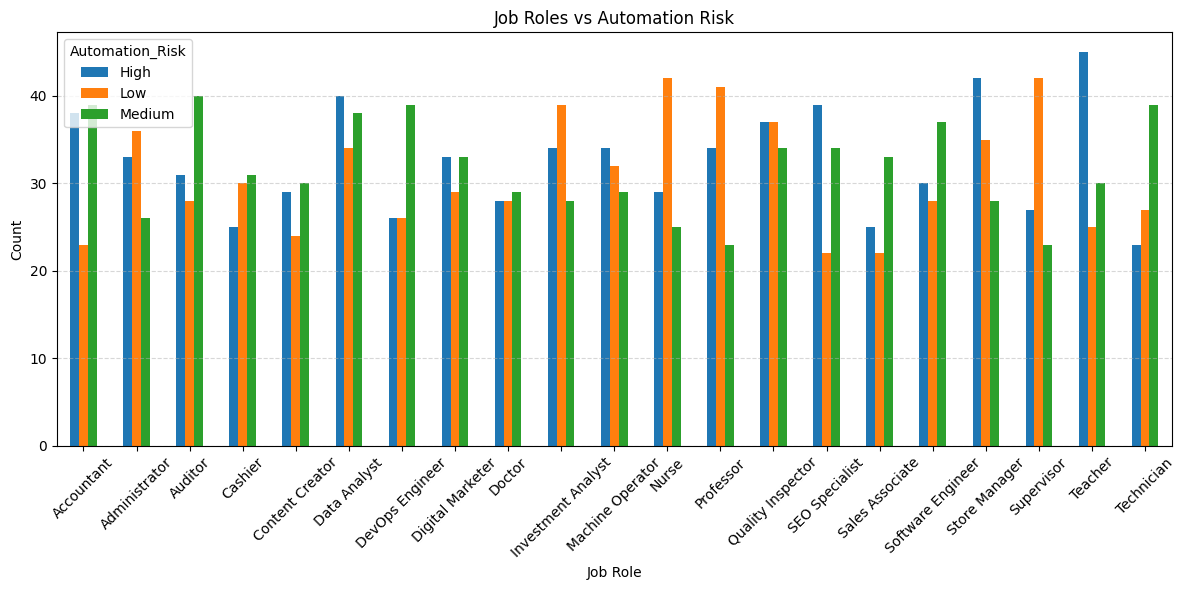

In [77]:
import matplotlib.pyplot as plt

pivot = df.pivot_table(index='Job_Role',
                       columns='Automation_Risk',
                       aggfunc='size',
                       fill_value=0)

pivot.plot(kind='bar', figsize=(12,6))

plt.title("Job Roles vs Automation Risk")
plt.xlabel("Job Role")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

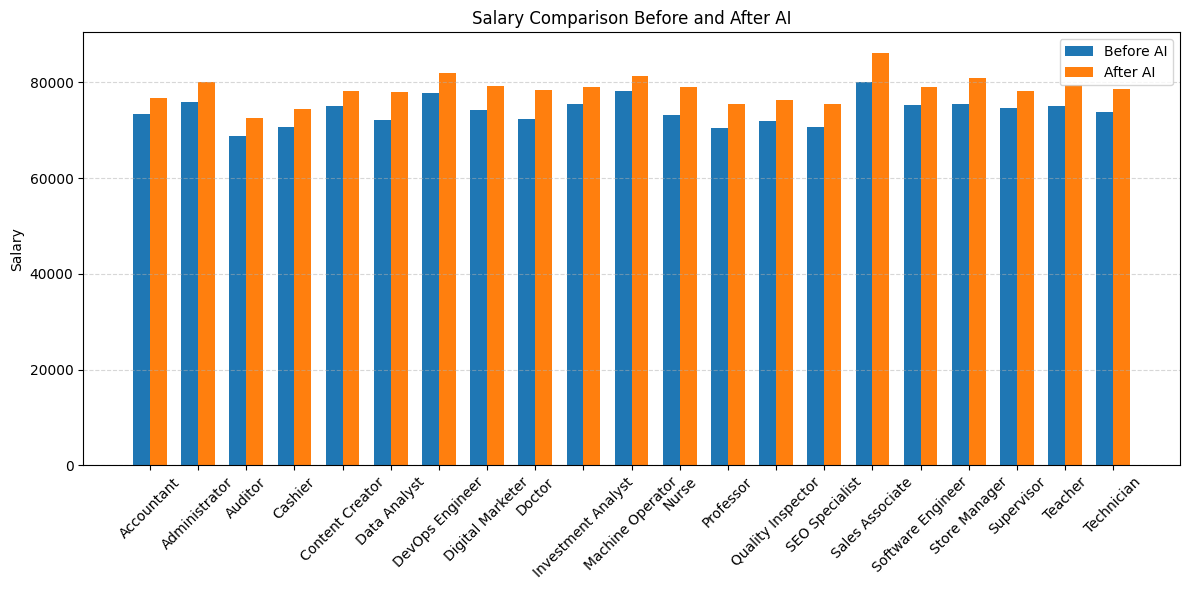

In [78]:

import matplotlib.pyplot as plt
import numpy as np

grouped = df.groupby('Job_Role')[['Salary_Before_AI', 'Salary_After_AI']].mean()

x = np.arange(len(grouped))
width = 0.35

plt.figure(figsize=(12,6))

plt.bar(x - width/2, grouped['Salary_Before_AI'], width, label='Before AI')
plt.bar(x + width/2, grouped['Salary_After_AI'], width, label='After AI')

plt.xticks(x, grouped.index, rotation=45)
plt.ylabel("Salary")
plt.title("Salary Comparison Before and After AI")
plt.legend()

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

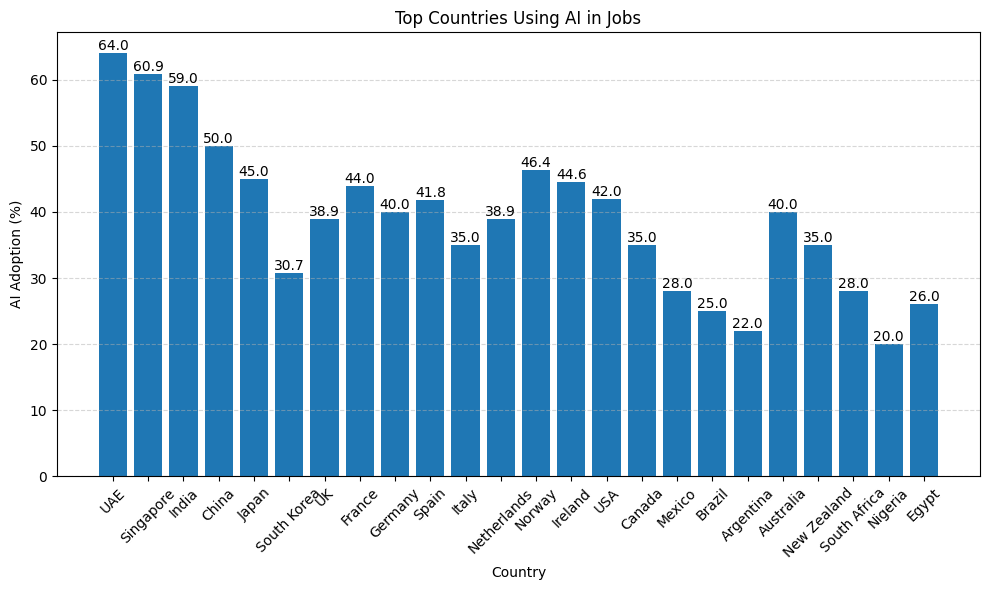

In [82]:
plt.figure(figsize=(10,6))

bars = plt.bar(df_country['Country'], df_country['AI_Adoption_%'])

plt.title("Top Countries Using AI in Jobs")
plt.xlabel("Country")
plt.ylabel("AI Adoption (%)")

plt.xticks(rotation=45)

# Add values
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height, height,
             ha='center', va='bottom')

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

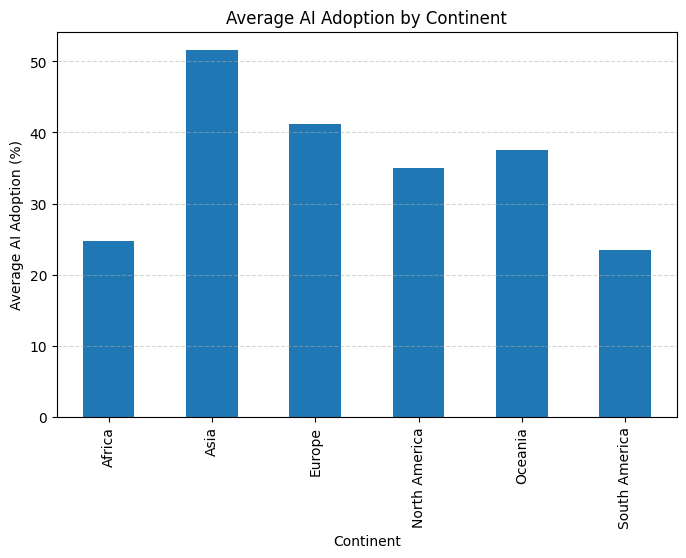

In [83]:
continent_data = df_country.groupby('Continent')['AI_Adoption_%'].mean()




In [91]:
grouped = df.groupby('AI_Adoption_Level')['Work_Hours_Per_Week'].mean()

print(grouped)

AI_Adoption_Level
High      44.804255
Low       44.857605
Medium    44.893648
Name: Work_Hours_Per_Week, dtype: float64


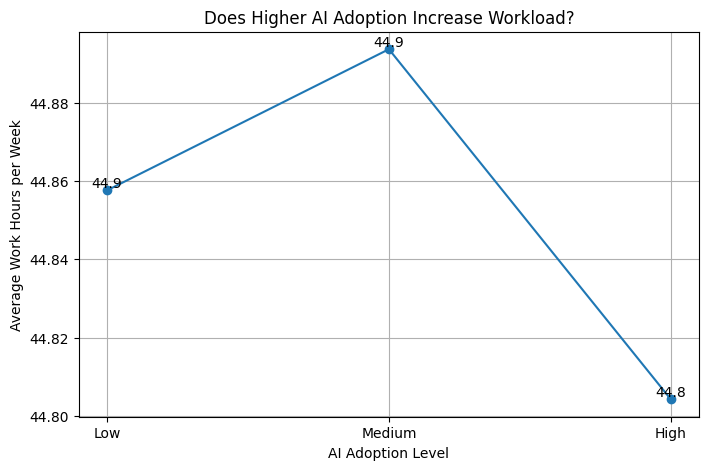

In [94]:
import matplotlib.pyplot as plt

# Order the levels properly
order = ['Low', 'Medium', 'High']

grouped = df.groupby('AI_Adoption_Level')['Work_Hours_Per_Week'].mean()
grouped = grouped.reindex(order)

plt.figure(figsize=(8,5))

plt.plot(grouped.index, grouped.values, marker='o')

# Add value labels
for i, val in enumerate(grouped.values):
    plt.text(i, val, round(val,1), ha='center', va='bottom')

plt.title("Does Higher AI Adoption Increase Workload?")
plt.xlabel("AI Adoption Level")
plt.ylabel("Average Work Hours per Week")

plt.grid(True)

plt.show()